In [78]:
import pandas as pd
import numpy as np
import joblib 
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
%matplotlib inline

In [27]:

df =pd.read_csv('diabetes.csv')
df

,PatientID,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,SerumInsulin,BMI,DiabetesPedigree,Age,Diabetic
0,1,5,164,110,257,35.6,1.12,73,0
1,2,9,127,109,251,27.0,0.52,76,0
2,3,0,127,72,210,20.3,0.75,37,0
3,4,10,76,110,87,32.8,0.82,53,0
4,5,7,178,110,255,18.4,0.90,42,1
...,...,...,...,...,...,...,...,...,...
9995,9996,2,146,63,172,30.3,1.59,21,1
9996,9997,9,76,73,39,18.1,1.59,19,0
9997,9998,4,129,83,160,16.3,0.44,53,0
9998,9999,5,193,75,212,45.5,1.17,18,0


In [3]:
df.info


<bound method DataFrame.info of       PatientID  Pregnancies  PlasmaGlucose  DiastolicBloodPressure  \
0             1            5            164                     110   
1             2            9            127                     109   
2             3            0            127                      72   
3             4           10             76                     110   
4             5            7            178                     110   
...         ...          ...            ...                     ...   
9995       9996            2            146                      63   
9996       9997            9             76                      73   
9997       9998            4            129                      83   
9998       9999            5            193                      75   
9999      10000            8            186                      78   

      SerumInsulin   BMI  DiabetesPedigree  Age  Diabetic  
0              257  35.6              1.12   73        

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   PatientID               10000 non-null  int64  
 1   Pregnancies             10000 non-null  int64  
 2   PlasmaGlucose           10000 non-null  int64  
 3   DiastolicBloodPressure  10000 non-null  int64  
 4   SerumInsulin            10000 non-null  int64  
 5   BMI                     10000 non-null  float64
 6   DiabetesPedigree        10000 non-null  float64
 7   Age                     10000 non-null  int64  
 8   Diabetic                10000 non-null  int64  
dtypes: float64(2), int64(7)
memory usage: 703.3 KB


In [5]:
df.columns[1]

'Pregnancies'

In [6]:
df.dtypes

PatientID                   int64
Pregnancies                 int64
PlasmaGlucose               int64
DiastolicBloodPressure      int64
SerumInsulin                int64
BMI                       float64
DiabetesPedigree          float64
Age                         int64
Diabetic                    int64
dtype: object

In [7]:
df.ndim

2

In [8]:
df.pivot_table(index='A', columns='B', values='C')

KeyError: 'C'

In [ ]:
df.describe()

In [ ]:
df.columns

In [ ]:
count = df.count()
count

In [ ]:
count =len(df)
print(f' Analyzing {count} rows of data')

In [10]:
diabetic_count=df['Diabetic'].value_counts()
print(diabetic_count)

Diabetic
0    6491
1    3509
Name: count, dtype: int64


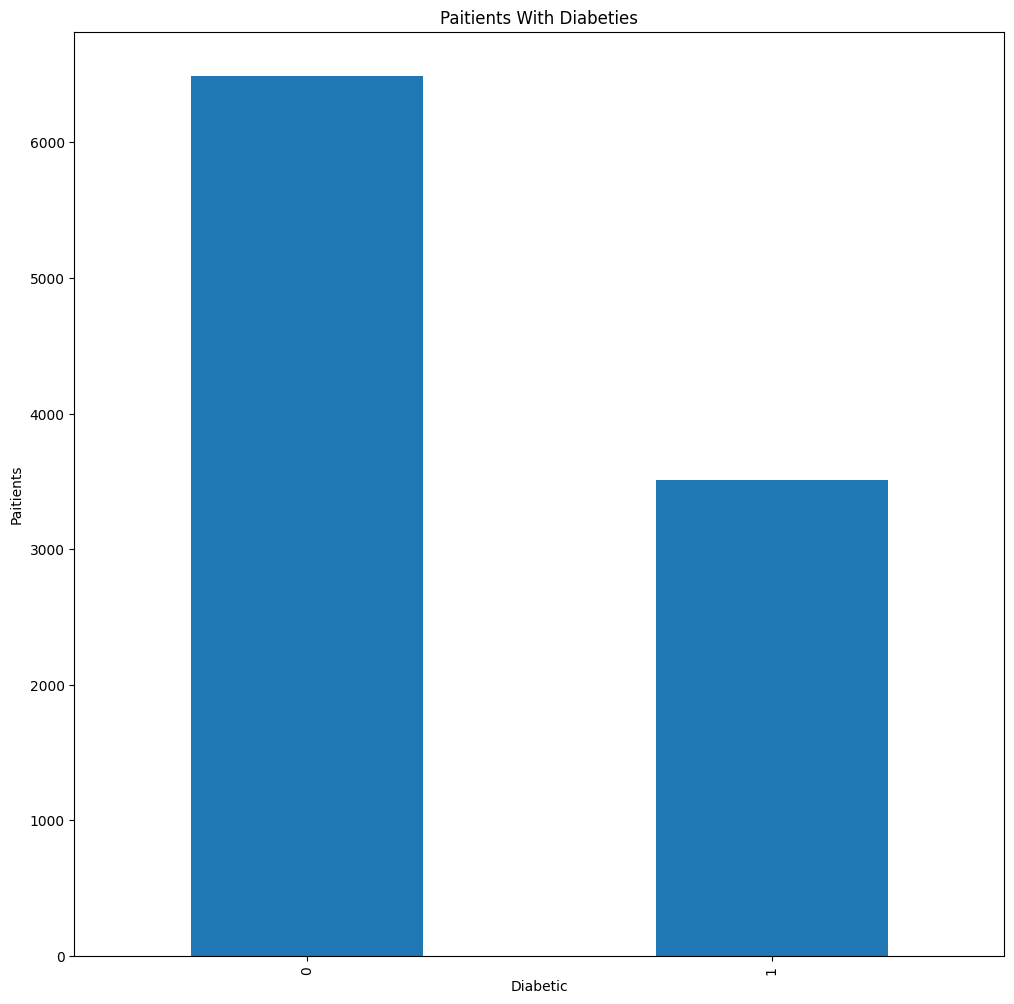

In [45]:
fig = plt.figure(figsize=(12,12))
ax =fig.gca()
ax.set_title("Paitients With Diabeties")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Paitients")
diabetic_count.plot.bar()
plt.show()
fig.savefig("Diabeties.png")
plt.close(fig)

In [ ]:
###separating Features and Target or label
# x fearutres and y is target or label in the df.columns output
x,y =df[[ 'Pregnancies', 'PlasmaGlucose', 'DiastolicBloodPressure',
       'SerumInsulin', 'BMI', 'DiabetesPedigree', 'Age']].values,df['Diabetic'].values

In [13]:
x

array([[5.00e+00, 1.64e+02, 1.10e+02, ..., 3.56e+01, 1.12e+00, 7.30e+01],
       [9.00e+00, 1.27e+02, 1.09e+02, ..., 2.70e+01, 5.20e-01, 7.60e+01],
       [0.00e+00, 1.27e+02, 7.20e+01, ..., 2.03e+01, 7.50e-01, 3.70e+01],
       ...,
       [4.00e+00, 1.29e+02, 8.30e+01, ..., 1.63e+01, 4.40e-01, 5.30e+01],
       [5.00e+00, 1.93e+02, 7.50e+01, ..., 4.55e+01, 1.17e+00, 1.80e+01],
       [8.00e+00, 1.86e+02, 7.80e+01, ..., 3.13e+01, 1.10e-01, 4.20e+01]],
      shape=(10000, 7))

In [47]:
y

array([0, 0, 0, ..., 0, 0, 1], shape=(10000,))

In [15]:
### Split Data in to training and testing sets
train_test_split(x, y, test_size=0.2, random_state=42)

[array([[  2.  , 154.  ,  69.  , ...,  41.4 ,   1.36,  54.  ],
        [  8.  , 153.  ,  47.  , ...,  42.6 ,   1.64,  32.  ],
        [  8.  , 137.  ,  81.  , ...,  34.2 ,   1.97,  41.  ],
        ...,
        [  8.  ,  96.  ,  94.  , ...,  46.3 ,   1.15,  21.  ],
        [ 12.  , 152.  , 120.  , ...,  49.8 ,   1.71,  33.  ],
        [ 14.  , 177.  , 115.  , ...,  45.  ,   0.53,  42.  ]],
       shape=(8000, 7)),
 array([[ 11.  , 175.  , 117.  , ...,  33.2 ,   2.  ,  21.  ],
        [  2.  , 180.  , 106.  , ...,  31.2 ,   1.6 ,  78.  ],
        [  0.  , 167.  , 103.  , ...,  17.1 ,   2.2 ,  35.  ],
        ...,
        [  5.  , 161.  , 103.  , ...,  23.2 ,   0.33,  51.  ],
        [  7.  , 103.  ,  75.  , ...,  17.3 ,   1.96,  45.  ],
        [ 11.  , 157.  ,  86.  , ...,  30.1 ,   2.04,  34.  ]],
       shape=(2000, 7)),
 array([1, 1, 1, ..., 0, 0, 0], shape=(8000,)),
 array([0, 0, 0, ..., 1, 0, 0], shape=(2000,))]

In [37]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [48]:
print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))

7000
3000
7000
3000


In [59]:
linear_regression = LinearRegression()
linear_regression.fit(x_train,y_train)
print(linear_regression)

LinearRegression()


In [60]:
print(linear_regression.intercept_)  #this is the model which understood the relatio between the features and the target

0.443133654620839


In [61]:
### you model is ready linnear_regression is your model now ask for prediction by giving test data

prediction =linear_regression.predict(x_test)
print('prediction is',prediction)

prediction is [0.32395117 0.32640164 0.34967891 ... 0.32968167 0.31613861 0.39564333]


In [52]:
logistic_regression=LogisticRegression()
logistic_regression.fit(x_train,y_train)
predictionslogical=logistic_regression.predict(x_test)
print(predictionslogical)

[0 0 0 ... 0 0 0]


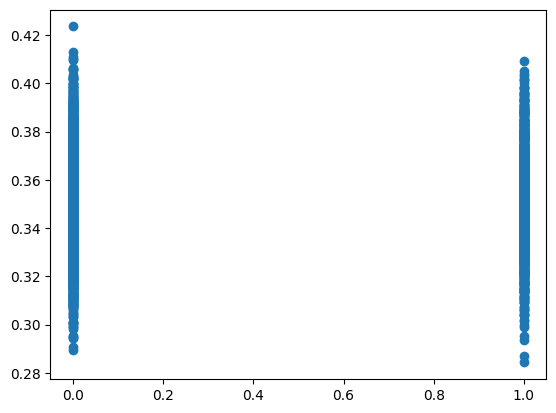

In [63]:
plt.scatter(y_test,prediction)
plt.show()

In [51]:
### Compare predictions results with y_test
y_test

array([0, 0, 0, ..., 1, 0, 1], shape=(3000,))

In [53]:
y_test

array([0, 0, 0, ..., 1, 0, 1], shape=(3000,))

In [65]:
accuracylinear=np.average(prediction==y_test)
print(accuracylinear)

0.0


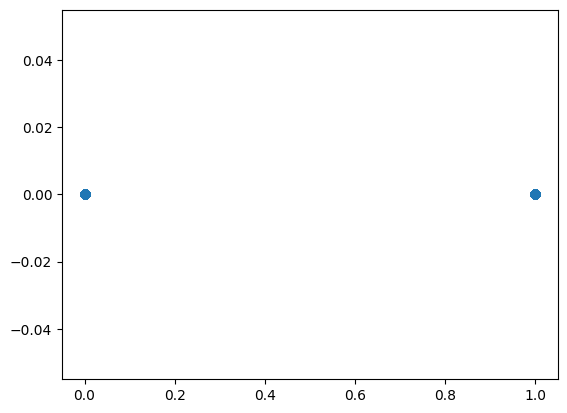

In [64]:
plt.scatter(y_test,predictionslogical)
plt.show()

In [57]:
### get accuracy using numpy

accuracy=np.average(predictionslogical==y_test)
print(accuracy)

0.652


In [58]:
### 60 % accuracy

In [75]:
### Test model for new Data single paitient
#'Pregnancies', 'PlasmaGlucose', 'DiastolicBloodPressure',
#       'SerumInsulin', 'BMI', 'DiabetesPedigree', 'Age']].values,df['Diabetic'].values

x_new =[[0,200,75,24,50,1.2,40]]
prediction_newpaitient=logistic_regression.predict(x_new)
prediction_newpaitient
#print(prediction_newpaitient)

array([0])

In [76]:
##copy any one row from actual data

x_newActualRow =[[7,178,110,255,18.4,0.9,42]]
prediction_actualrow=logistic_regression.predict(x_newActualRow )
prediction_newpaitient

array([0])

In [84]:
x_newActulRowDia =[[7,278,110,255,18.4,0.90,42]]

prediction_actualrowdia=logistic_regression.predict(x_newActulRowDia )
prediction_actualrowdia

array([0])

In [80]:
### do pickling to save model to be used later
joblib.dump(logistic_regression, 'logistic_regression.pkl')
print('logistic regresion saved')

logistic regresion saved


## model = joblib.load('logistic_regression.pkl')
x_newData =[[8,186,78,174,31.3,0.11,42]]
predictModel =model.predict(x_newData)

classname=['Non-Diabetic','Diabetic'] 
predicted_classes = []

for pred in  predictModel:
    predicted_classes.append(classname[pred])
print('input ::',x_newData)
print('ouput:::',predicted_classes)
predictModel